# What are the most demanded skills for the top 3 most popular data roles?

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   
import numpy as np
import ast


from datasets import load_dataset

loaded_dataset = load_dataset("lukebarousse/data_jobs")

df = loaded_dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)

In [ ]:
df_UK = df[df['job_country'] == 'United Kingdom']

In [ ]:
df_skills = df_UK.explode('job_skills')

df_skills[['job_title', 'job_skills']]

In [ ]:
df_skills_count = df_skills.groupby(['job_title_short', 'job_skills']).size().reset_index(name='skills_count')

df_skills_count = df_skills_count.sort_values(by='skills_count', ascending=False)

df_skills_count

In [38]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = ['Data Scientist', 'Data Engineer', 'Data Analyst']

job_titles

['Data Scientist', 'Data Engineer', 'Data Analyst']

In [ ]:
df_job_title_count = df_UK['job_title_short'].value_counts().reset_index(name='job_total')

df_job_title_count

In [ ]:
df_skills_perc = pd.merge(df_skills_count,df_job_title_count, how = 'left', on = 'job_title_short')

df_skills_perc['skills_perc'] = (df_skills_perc['skills_count'] / df_skills_perc['job_total']) * 100

df_skills_perc.head(5)

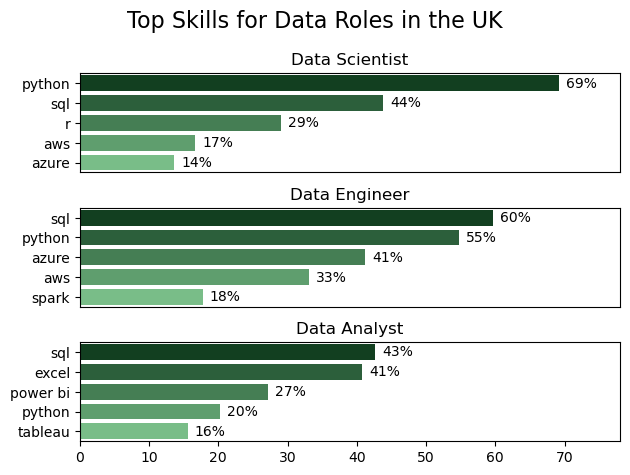

In [39]:
fig, ax = plt.subplots(3, 1,)
 
GREEN_PALETTE = [
    "#0A461E",  # Dark green
    "#236737",  # Deep green
    "#3C8750",  # Medium green
    "#55A869",  # Light green
    "#6EC882"   # Bright green
]

for i, job_title in enumerate (job_titles):

    df_plot = df_skills_perc[df_skills_perc["job_title_short"] == job_title].head(5)
    sns.barplot(
        data=df_plot,
        x='skills_perc',
        y='job_skills',
        ax=ax[i],
        hue='job_skills',
        palette=GREEN_PALETTE
    )
    ax[i].set_title(job_titles[i])
    ax[i].set_ylabel("")
    ax[i].set_xlabel("")
    #ax[i].legend().remove()
    ax[i].set_xlim(0, 78)

    for n, v in enumerate(df_plot['skills_perc']):
        ax[i].text(v + 1, n, f"{v:.0f}%", va='center')

    if i < 2:
        ax[i].set_xticks([])

plt.suptitle('Top Skills for Data Roles in the UK', fontsize=16)
plt.tight_layout()
plt.show()